# Projection Distortion Map (indicatrix)

**Family:** Correlation &nbsp;|&nbsp; **Library:** matplotlib / seaborn &nbsp;|&nbsp; **Level:** Advanced

> *Correlation:* Show the relationship between two or more variables.

## Design purpose

Overlays small ellipses on a 2-D embedding (t-SNE, UMAP, PCA) to show where and in which direction the projection stretches or squeezes the original high-dimensional space. It borrows Tissot's indicatrix from cartography: on a world map, Tissot's circles reveal that Greenland is inflated; here the ellipses reveal which clusters look tighter or looser than they really are.

## When to use

- Before reading cluster size, spread or gaps from a t-SNE or UMAP map
- Compare which regions of an embedding are trustworthy
- Explain to an audience why embedding distances should not be read literally

## Avoid when

- Linear projections like PCA, whose distortion is uniform and simpler to state
- Sparse embeddings with only a few points per region; the local fits become unstable
- A general audience that only needs to see the clusters

## Alternatives

- Dimension reduction comparison (t-SNE, UMAP, PaCMAP side by side)
- Trustworthiness / neighbour-preservation scores
- PCA biplot

## Design tips

- What it adds: a plain embedding hides its own distortions; the indicatrix shows them in place
- Each ellipse is the 2-D image of a small high-dimensional ball around that spot. A large ellipse means the map spreads that region out; an elongated one means it is stretched in one direction
- Colour shows the ratio of high-D to 2-D neighbour distances, relative to the whole map: orange = compressed (more different than it looks), blue = stretched (more similar than it looks), gray = faithful
- This is a simplified re-implementation: a least-squares local linear map from 2-D neighbour offsets to high-D offsets in each grid cell. The original Hypertrix code and metric were questioned by a 2026 preprint (FADEx, arXiv 2607.27463), so treat the ellipses as a qualitative guide

## Example

A t-SNE map of the real handwritten-digits dataset that ships with scikit-learn (1,797 images, 64 dimensions), with distortion ellipses on a regular grid.

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from matplotlib.patches import Ellipse
from scipy.spatial.distance import pdist
from sklearn.datasets import load_digits
from sklearn.manifold import TSNE
from sklearn.neighbors import NearestNeighbors

### Data

In [2]:
digits = load_digits()
X = digits.data / 16
labels = digits.target
emb = TSNE(n_components=2, perplexity=30, init="pca", random_state=0).fit_transform(X)
pd.DataFrame(emb, columns=["tsne1", "tsne2"]).describe().round(1)

,tsne1,tsne2
count,1797.0,1797.0
mean,-0.1,-0.5
std,25.7,27.2
min,-47.2,-62.7
25%,-22.3,-20.3
50%,0.6,3.5
75%,15.6,16.7
max,52.4,49.6


### Plot

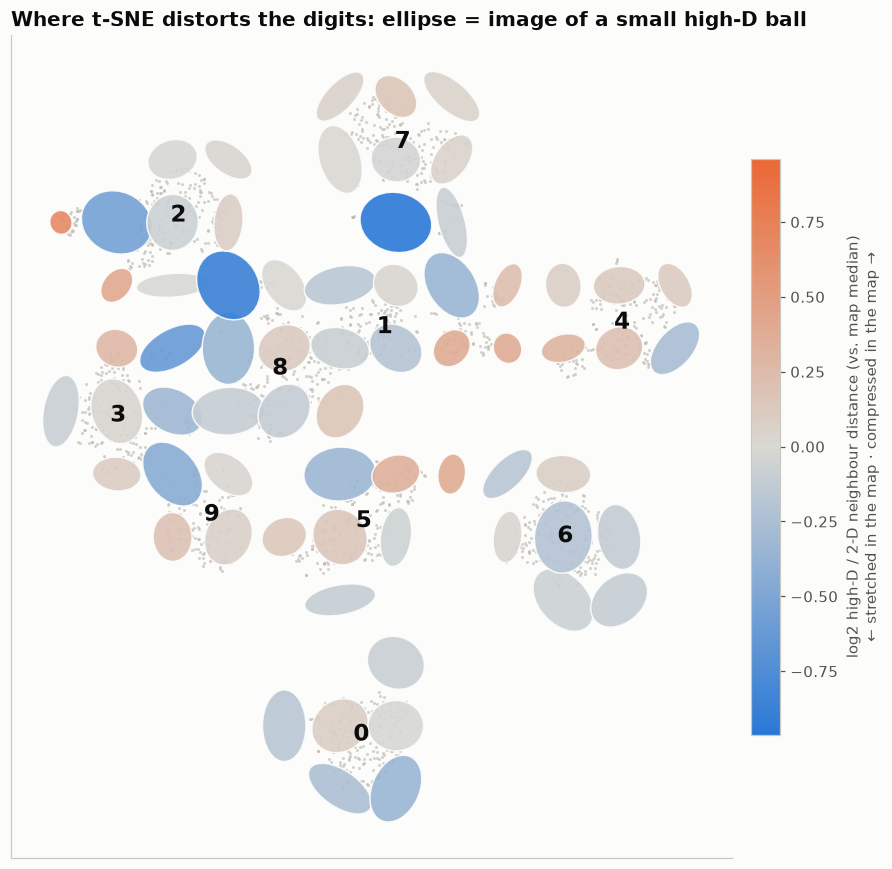

In [3]:
G, k = 12, 25                                  # grid resolution, neighbours per local fit
lo, hi = emb.min(0), emb.max(0)
cell = (hi - lo).max() / (G - 1)
gx, gy = np.meshgrid(np.linspace(lo[0], hi[0], G), np.linspace(lo[1], hi[1], G))
centers = np.c_[gx.ravel(), gy.ravel()]
dist, idx = NearestNeighbors(n_neighbors=k).fit(emb).kneighbors(centers)

glyphs = []
for c, d, nb in zip(centers, dist, idx):
    if d.max() > 0.9 * cell:                   # too few points nearby: skip empty regions
        continue
    U = emb[nb] - emb[nb].mean(0)              # 2-D offsets
    V = X[nb] - X[nb].mean(0)                  # high-D offsets
    M, *_ = np.linalg.lstsq(U, V, rcond=None)  # local linear map 2-D -> high-D (2 x 64)
    evals, evecs = np.linalg.eigh(M @ M.T)     # metric tensor: high-D length per unit 2-D length
    ratio = pdist(X[nb]).mean() / pdist(emb[nb]).mean()
    glyphs.append((c, np.sqrt(np.maximum(evals, 1e-12)), evecs, ratio))

ratios = np.array([g[3] for g in glyphs])
scales = np.array([g[1].mean() for g in glyphs])
log_ratio = np.log2(ratios / np.median(ratios))
cmap = LinearSegmentedColormap.from_list("stretch", [PALETTE[0], "#d9d8d3", PALETTE[1]])
lim = np.abs(log_ratio).max()
norm = TwoSlopeNorm(0, -lim, lim)

fig, ax = plt.subplots(figsize=(9, 8))
ax.scatter(emb[:, 0], emb[:, 1], s=4, color="#b8b7b1", alpha=0.6, linewidth=0)
base = 0.36 * cell
for (c, s, vecs, _), lr in zip(glyphs, log_ratio):
    semi = np.clip(base * np.median(scales) / s, 0.25 * base, 1.6 * base)  # image of a fixed high-D ball
    angle = np.degrees(np.arctan2(vecs[1, 0], vecs[0, 0]))
    ax.add_patch(Ellipse(c, 2 * semi[0], 2 * semi[1], angle=angle, facecolor=cmap(norm(lr)),
                         edgecolor="#fcfcfb", linewidth=1, alpha=0.9))
for d in range(10):
    cx, cy = np.median(emb[labels == d], axis=0)
    ax.text(cx, cy, str(d), ha="center", va="center", fontsize=15, fontweight="bold", color="#0b0b0b")
sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap)
cb = fig.colorbar(sm, ax=ax, shrink=0.7, pad=0.02)
cb.set_label("log2 high-D / 2-D neighbour distance (vs. map median)\n← stretched in the map · compressed in the map →")
ax.set_xticks([])
ax.set_yticks([])
ax.grid(False)
ax.set_aspect("equal")
ax.set_title("Where t-SNE distorts the digits: ellipse = image of a small high-D ball")
fig.tight_layout()
plt.show()

## How to read it

Inside most digit clusters the ellipses are gray: locally the map is faithful. The large blue ellipses sit in the gaps and bridges between clusters (for example between 2 and 8, and below 7): t-SNE has spread those regions out, exaggerating how separate the digits are. Orange ellipses sit on cluster edges, where the map squeezes a lot of variety into a small area.

## Reference

This method comes from the research literature:

- Raval, S., Viégas, F. & Wattenberg, M. (2024). Hypertrix: An indicatrix for high-dimensional visualizations. IEEE VIS 2024 (Short Papers), Best Paper Award. <https://doi.org/10.1109/VIS55277.2024.00073>

---
Standalone script: [`projection_distortion.py`](projection_distortion.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)